# 02 | Exploratory workload analysis

**Motive:** Describe VM load, temporal dependence, segment differences and the components of high-load periods.

**Logic:** Analyze distributions, temporal behavior, category/core/memory combinations, concentration and threshold-defined windows using training timestamps only. Relative hours are measured from trace start.

Code cells retain the computed tables and plots. Findings and operational interpretations are recorded after the corresponding evidence in the [final report](../reports/report.md).


## Setup | Reuse the verified preprocessing and target pipeline

Build the full target grid first, apply the existing chronological split, and pass only the training timestamps to the EDA functions. The analysis function filters reading rows to those timestamps again and checks that their aggregates match the training targets.


In [1]:
from pathlib import Path
import os
import json
import logging
import pandas as pd
import numpy as np
from IPython.display import HTML, Markdown, display

ROOT = Path.cwd()
if not (ROOT / "challenge_data").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "challenge_data").is_dir(), "Run from the repository or notebooks directory"
os.environ["MPLCONFIGDIR"] = str(ROOT / "artifacts" / "matplotlib")
import matplotlib.pyplot as plt
from cwfc.io import verify_checksums, load_readings, load_metadata
from cwfc.targets import build_targets, split_train_holdout
from cwfc.eda import (analyze_workload, plot_distributions, plot_temporal,
    plot_correlations, plot_segments, plot_concentration, plot_peak_drivers, save_figure)

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
FIGURES = ROOT / "reports" / "figures"
TABLES = ROOT / "artifacts" / "workload_analysis"
TABLES.mkdir(parents=True, exist_ok=True)
verify_checksums(ROOT / "challenge_data")
readings = load_readings(ROOT / "challenge_data")
metadata = load_metadata(ROOT / "challenge_data")
full_targets = build_targets(readings, metadata)
train_targets, holdout_targets = split_train_holdout(full_targets, min_train=48)
analysis = analyze_workload(readings, metadata, train_targets)
m = analysis["metrics"]

analysis_boundary = pd.DataFrame([
    ("Training", len(train_targets), int(train_targets.timestamp.min()), int(train_targets.timestamp.max())),
    ("Holdout (timestamps only)", len(holdout_targets), int(holdout_targets.timestamp.min()), int(holdout_targets.timestamp.max())),
], columns=["Window", "Rows", "First relative second", "Last relative second"])
display(analysis_boundary.style.hide(axis="index"))


INFO: Excluded 0 incomplete CPU readings (no imputation)


INFO: Averaging 0 duplicate VM/timestamp rows


INFO: Excluded 0 incomplete CPU readings (no imputation)


INFO: Averaging 0 duplicate VM/timestamp rows


Window,Rows,First relative second,Last relative second
Training,110,0,32700
Holdout (timestamps only),24,33000,39900


## 1. Distributions | Per-VM mean, peak, idle, steady and hot behavior

**Logic.** For each VM, compute the mean and sample standard deviation of its training `avg_cpu`, and the maximum of its training `max_cpu`. The histograms use logarithmic CPU axes to show both small and large utilization levels. Zero values cannot be plotted on a log axis; their counts are stated on the charts.

Use these fixed descriptive rules:

- **Idle:** mean CPU below 5%.
- **Steady:** mean CPU at least 5% and coefficient of variation (`std / mean`) at most 0.5.
- **Hot:** at least one interval with `max_cpu > 80%`.

These are **overlapping indicators**, not an exhaustive classification. A VM can be idle on average and still have a brief hot interval; a steady VM can also be hot. The 0.5 CV cutoff is an explicit descriptive convention, not a tuned forecast parameter.


Indicator,Rule,VMs,Share of selected VMs (%)
Idle,historical CPU average avg_cpu < 5%,"4,635",46.35
Steady,historical CPU average >= 5% and std/mean <= 0.5,"4,495",44.95
Hot,At least one training max_cpu > 80%,"2,235",22.35


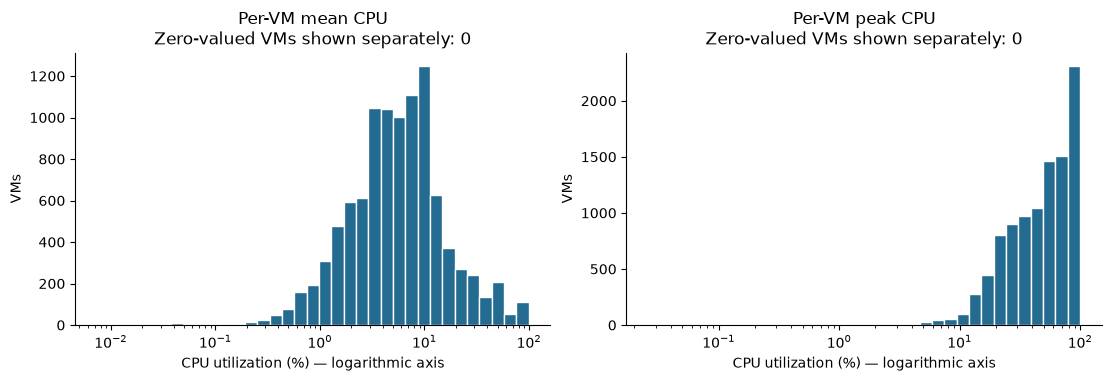

Measure,Value
Median VM mean CPU (%),5.5017
VMs both idle and hot,151.0000
VM count in the top 1%,100.0000
Top 1% share of CPU sum (%),9.5964


In [2]:
display(analysis["indicators"].rename(columns={"indicator":"Indicator", "rule":"Rule", "vm_count":"VMs", "share_pct":"Share of selected VMs (%)"})
    .style.hide(axis="index").format({"VMs":"{:,}", "Share of selected VMs (%)":"{:.2f}"}))
vm = analysis["vm_statistics"]
fig = plot_distributions(analysis)
save_figure(fig, FIGURES, "workload_distributions.png")
plt.show()

distribution_summary = pd.DataFrame([
    ("Median VM mean CPU (%)", vm.mean_cpu.median()),
    ("VMs both idle and hot", m["idle_and_hot_vms"]),
    ("VM count in the top 1%", m["top_1pct_vm_count"]),
    ("Top 1% share of CPU sum (%)", m["top_1pct_cpu_share_pct"]),
], columns=["Measure", "Value"])
display(distribution_summary.style.hide(axis="index").format({"Value": "{:,.4f}"}))


## 2. Temporal behavior | Level, persistence and regime changes

**Logic.** Plot aggregate mean CPU with a band at the **historical CPU average ±2 sample standard deviations**. This band describes observed variation; it is neither a confidence interval nor a forecast interval. Compare a trailing 6-sample (30-minute) mean and sample variance; the first two samples have no rolling result, then the initial windows contain 3–5 samples before reaching six.

For the **change-point scan**, move a boundary across training data and subtract the preceding six-sample mean from the following six-sample mean. Positive values suggest an upward shift; negative values suggest a downward shift. Report the six largest separated local maxima of absolute change (minimum separation: six eligible boundaries). Missing values invalidate the affected comparisons.

The scan is **retrospective**: it uses observations on both sides of a boundary. Candidate shifts are descriptive, not statistically confirmed change points or real-time forecast signals.


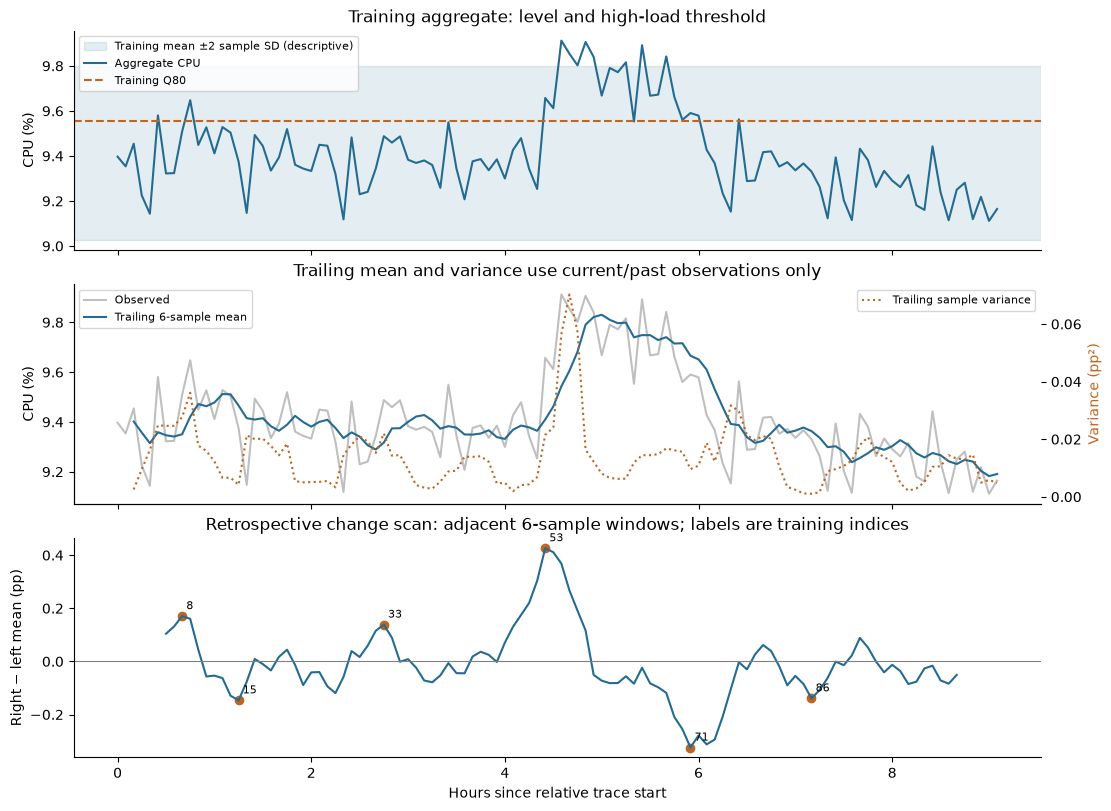

Training boundary index,Relative seconds,Right minus left mean (pp),Absolute change (pp)
8,2400,0.1706,0.1706
15,4500,-0.1466,0.1466
33,9900,0.1383,0.1383
53,15900,0.4263,0.4263
71,21300,-0.3243,0.3243
86,25800,-0.1392,0.1392


In [3]:
fig = plot_temporal(analysis)
save_figure(fig, FIGURES, "workload_temporal.png")
plt.show()
display(analysis["change_candidates"].rename(columns={"boundary_index":"Training boundary index", "timestamp":"Relative seconds", "change_pp":"Right minus left mean (pp)", "absolute_change_pp":"Absolute change (pp)"})
    .style.hide(axis="index").format({"Right minus left mean (pp)":"{:.4f}", "Absolute change (pp)":"{:.4f}"}))
scan = analysis["change_scan"]
up = scan.loc[scan.change_pp.idxmax()]
down = scan.loc[scan.change_pp.idxmin()]


### ACF and PACF | Does persistence appear after aggregation?

**Logic.** At each lag, ACF compares mean-centered observations with earlier observations and divides by the full centered sum of squares. Use the same unadjusted definition for the aggregate and each VM, then take the median VM ACF. Constant/insufficient VM traces have undefined correlation and are excluded; missing timestamps keep their positions.

PACF uses the Yule–Walker method on the complete aggregate, to describe remaining dependence after accounting for shorter lags. On replacement data with missing aggregate values, PACF is omitted rather than filling observations or compressing the time grid. These are descriptive estimates over a short window; PACF estimates are limited to complete training observations.


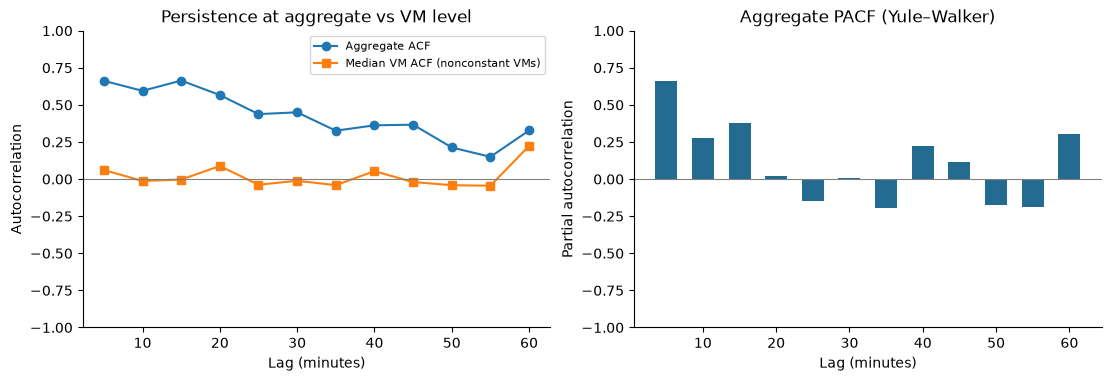

Lag (steps),Lag (minutes),Aggregate ACF,Aggregate PACF,Median VM ACF,Eligible VMs
1,5,0.662,0.662,0.061,10000
2,10,0.595,0.278,-0.013,10000
3,15,0.664,0.378,-0.003,10000
4,20,0.566,0.024,0.088,10000
5,25,0.438,-0.150,-0.038,10000
6,30,0.450,0.004,-0.012,10000
7,35,0.326,-0.197,-0.041,10000
8,40,0.362,0.223,0.053,10000
9,45,0.366,0.113,-0.020,10000
10,50,0.213,-0.174,-0.041,10000


In [4]:
fig = plot_correlations(analysis)
save_figure(fig, FIGURES, "workload_correlations.png")
plt.show()
display(analysis["correlations"].rename(columns={"lag":"Lag (steps)", "minutes":"Lag (minutes)", "aggregate_acf":"Aggregate ACF", "aggregate_pacf":"Aggregate PACF", "median_vm_acf":"Median VM ACF", "eligible_vms":"Eligible VMs"})
    .style.hide(axis="index").format({"Aggregate ACF":"{:.3f}", "Aggregate PACF":"{:.3f}", "Median VM ACF":"{:.3f}"}))
lag1 = analysis["correlations"].iloc[0]


## 3. Segments | Category × core bucket × memory bucket

**Logic.** Form observed combinations of workload category, core bucket and memory bucket. At each timestamp, compute mean CPU within the segment. Summarize:

- **Level:** mean of those timestamp-level means.
- **Volatility:** sample SD of those means, in percentage points.
- **High-load CPU share:** the segment's sum of VM `avg_cpu` at high-load timestamps divided by the corresponding sum across all segments.

High load is strictly above the training aggregate's Q80 (defined in section 4). Shares describe summed utilization percentages, not exact CPU resources. Also show category-level summaries, so small combinations can be interpreted in context. The chart shows the top 12 combinations by high-load contribution; the table shows the top 20, and a CSV stores all observed combinations.


Category,Mean CPU (%),Temporal SD (pp),Observed timestamps,VMs,High-load CPU share (%)
Interactive,11.505,0.243,110,3091,37.46
Unknown,10.355,0.629,110,729,7.74
Delay-insensitive,8.257,0.217,110,6180,54.80


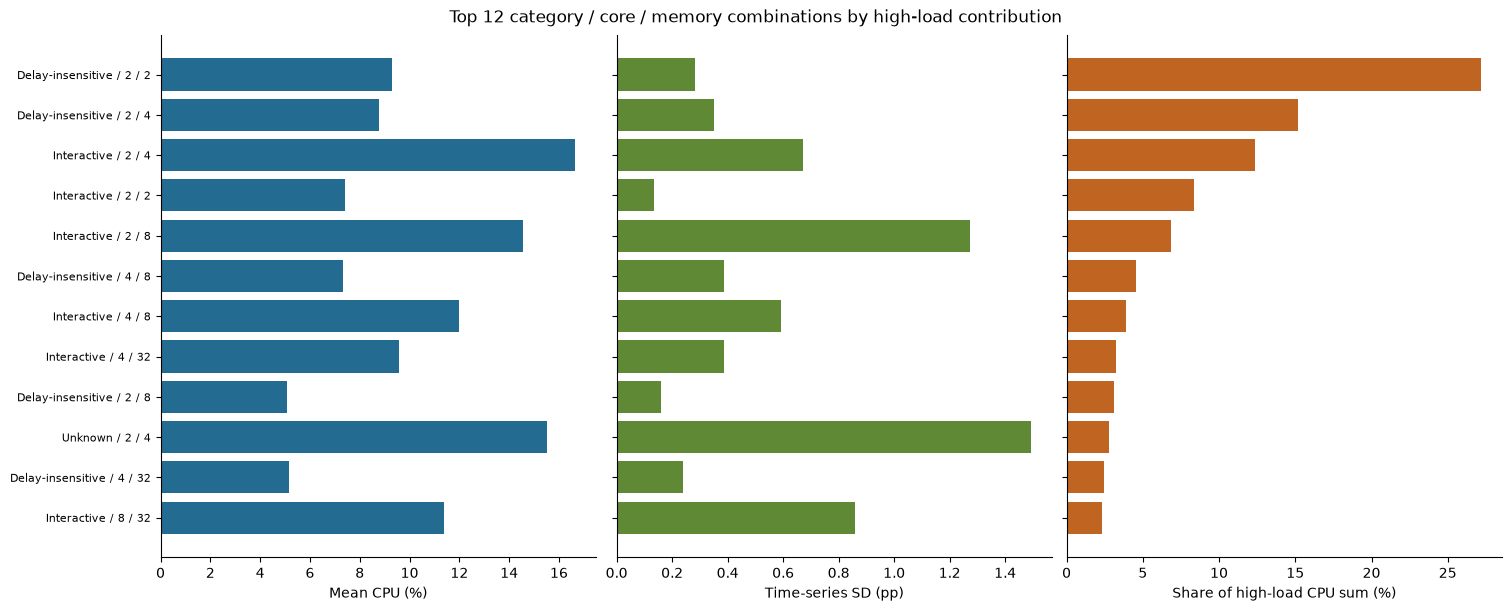

Category,Core bucket,Memory bucket,Mean CPU (%),Temporal SD (pp),Observed timestamps,VMs,High-load CPU share (%)
Delay-insensitive,2,2,9.303,0.284,110,2708,27.18
Delay-insensitive,2,4,8.762,0.352,110,1602,15.18
Interactive,2,4,16.639,0.670,110,697,12.35
Interactive,2,2,7.399,0.134,110,1087,8.37
Interactive,2,8,14.566,1.272,110,426,6.83
Delay-insensitive,4,8,7.335,0.388,110,585,4.53
Interactive,4,8,12.002,0.591,110,322,3.93
Interactive,4,32,9.559,0.387,110,331,3.23
Delay-insensitive,2,8,5.092,0.161,110,580,3.13
Unknown,2,4,15.503,1.493,110,176,2.80


In [5]:
display(analysis["categories"].rename(columns={"vm_category":"Category", "mean_cpu":"Mean CPU (%)", "volatility_pp":"Temporal SD (pp)", "timestamps_observed":"Observed timestamps", "vm_count":"VMs", "high_load_cpu_share_pct":"High-load CPU share (%)"})
    .style.hide(axis="index").format({"Mean CPU (%)":"{:.3f}", "Temporal SD (pp)":"{:.3f}", "High-load CPU share (%)":"{:.2f}"}))
fig = plot_segments(analysis)
save_figure(fig, FIGURES, "workload_segments.png")
plt.show()
display(analysis["segments"].nlargest(20, "high_load_cpu_share_pct").rename(columns={
    "vm_category":"Category", "virtual_core_bucket":"Core bucket", "memory_gb_bucket":"Memory bucket", "mean_cpu":"Mean CPU (%)", "volatility_pp":"Temporal SD (pp)", "timestamps_observed":"Observed timestamps", "vm_count":"VMs", "high_load_cpu_share_pct":"High-load CPU share (%)"})
    .style.hide(axis="index").format({"Mean CPU (%)":"{:.3f}", "Temporal SD (pp)":"{:.3f}", "High-load CPU share (%)":"{:.2f}"}))
category = analysis["categories"]
volatile = category.loc[category.volatility_pp.idxmax()]
important = analysis["segments"].sort_values("high_load_cpu_share_pct", ascending=False).iloc[0]


### Subscription and deployment concentration

**Logic.** Count distinct selected VMs per subscription/deployment, rank groups by size, and plot cumulative VM share. The table reports the largest group, top-ten share and the Herfindahl index (`sum(group_share²)`). Its reciprocal is the effective number of equally sized groups. These quantify concentration of the selected population, not the entire Azure fleet.


Grouping,Groups,Largest group: VMs,Largest group (%),Top 10 groups (%),HHI,Effective groups
subscription_id,2324,96,0.96,8.84,0.00282,355.0
deployment_id,2359,96,0.96,8.84,0.00281,356.0


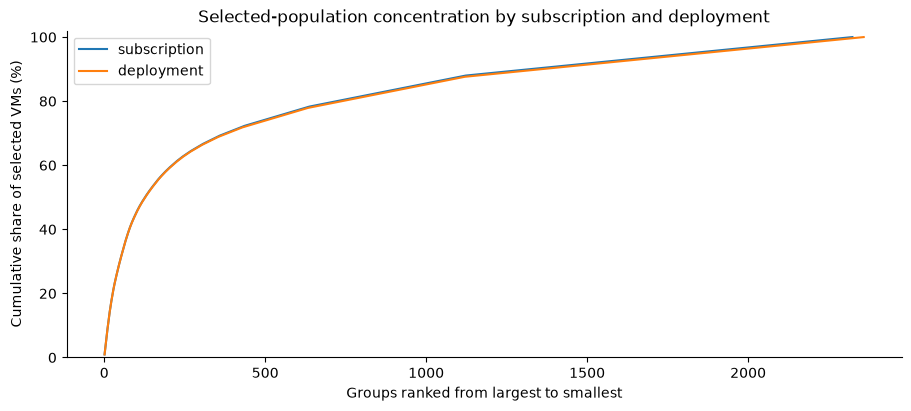

In [6]:
display(analysis["concentration"].rename(columns={"group":"Grouping", "distinct_groups":"Groups", "largest_group_vms":"Largest group: VMs", "largest_group_share_pct":"Largest group (%)", "top_10_group_share_pct":"Top 10 groups (%)", "hhi":"HHI", "effective_group_count":"Effective groups"})
    .style.hide(axis="index").format({"Largest group (%)":"{:.2f}", "Top 10 groups (%)":"{:.2f}", "HHI":"{:.5f}", "Effective groups":"{:.1f}"}))
fig = plot_concentration(analysis)
save_figure(fig, FIGURES, "workload_concentration.png")
plt.show()


## 4. Peaks and lows | Training thresholds, windows and drivers

**Logic.** Define **high load as aggregate CPU > training Q80** and **low load as aggregate CPU < training Q20**. Group consecutive selected timestamps into windows; ties at a threshold are excluded. These labels are relative to this training window, not absolute utilization or SLA limits.

For each high-load window, compare its mean with the immediately preceding six training slots (or fewer if near the beginning). A window starting at the first observation has no baseline and cannot be attributed this way.

**Driver calculation:** at each timestamp, a VM contributes `avg_cpu / observed_VM_count` to aggregate CPU. Average that contribution within the event and baseline, then subtract. VM contributions sum exactly to the aggregate mean change. Sum VM contributions within category for category drivers. This also works with changing observed populations; a zero contribution from an absent VM is an accounting term, not an imputed CPU reading. The attribution describes a change, not a causal mechanism.


In [7]:
threshold_table = pd.DataFrame([
    ("High load", "Greater than training Q80", m["high_threshold"]),
    ("Low load", "Less than training Q20", m["low_threshold"]),
], columns=["Label", "Rule", "CPU threshold (%)"])
display(threshold_table.style.hide(axis="index").format({"CPU threshold (%)": "{:.4f}"}))
peaks = analysis["peaks"].copy()
peaks["Index span"] = peaks.start_index.astype(str) + "–" + peaks.end_index.astype(str)
peaks["Relative hours"] = peaks.apply(lambda r: f"{r.start_seconds / 3600:.2f}–{r.end_seconds / 3600:.2f}", axis=1)
peaks["Top VM (ID prefix)"] = peaks.top_vm.astype(str).str[:12] + "…"
display(Markdown("### All high-load windows"))
display(peaks[["window_id", "Index span", "Relative hours", "samples", "mean_cpu", "baseline_cpu", "increase_pp"]]
    .rename(columns={"window_id":"Window", "samples":"Samples", "mean_cpu":"Mean CPU (%)", "baseline_cpu":"Prior-window CPU (%)", "increase_pp":"Change (pp)"})
    .style.hide(axis="index").format({"Mean CPU (%)":"{:.4f}", "Prior-window CPU (%)":"{:.4f}", "Change (pp)":"{:.4f}"}, na_rep="Not available"))
display(Markdown("### Leading drivers for every high-load window"))
display(peaks[["window_id", "baseline_samples", "top_category", "Top VM (ID prefix)", "top_20_vm_share_of_increase_pct"]]
    .rename(columns={"window_id":"Window", "baseline_samples":"Prior samples", "top_category":"Leading signed category", "top_20_vm_share_of_increase_pct":"Top 20 VM share of net rise (%)"})
    .style.hide(axis="index").format({"Top 20 VM share of net rise (%)":"{:.2f}"}, na_rep="No positive net rise"))
lows = analysis["lows"].copy()
lows["Index span"] = lows.start_index.astype(str) + "–" + lows.end_index.astype(str)
lows["Relative hours"] = lows.apply(lambda r: f"{r.start_seconds / 3600:.2f}–{r.end_seconds / 3600:.2f}", axis=1)
display(Markdown("### All low-load windows"))
display(lows[["window_id", "Index span", "Relative hours", "samples", "mean_cpu", "min_cpu"]]
    .rename(columns={"window_id":"Window", "samples":"Samples", "mean_cpu":"Mean CPU (%)", "min_cpu":"Min CPU (%)"})
    .style.hide(axis="index").format({"Mean CPU (%)":"{:.4f}", "Min CPU (%)":"{:.4f}"}))


Label,Rule,CPU threshold (%)
High load,Greater than training Q80,9.5545
Low load,Less than training Q20,9.2574


### All high-load windows

Window,Index span,Relative hours,Samples,Mean CPU (%),Prior-window CPU (%),Change (pp)
1,5–5,0.42–0.42,1,9.5803,9.3146,0.2657
2,9–9,0.75–0.75,1,9.6477,9.3506,0.2971
3,53–63,4.42–5.25,11,9.7847,9.3645,0.4202
4,65–72,5.42–6.00,8,9.6833,9.7400,-0.0567
5,77–77,6.42–6.42,1,9.5627,9.3918,0.1708


### Leading drivers for every high-load window

Window,Prior samples,Leading signed category,Top VM (ID prefix),Top 20 VM share of net rise (%)
1,5,Delay-insensitive,liNAO/NtVtqt…,40.13
2,6,Interactive,Qwlz2Bc4AVSz…,43.41
3,6,Delay-insensitive,xLbiuzphbqoX…,22.03
4,6,Interactive,OGT2cFkkc3pO…,No positive net rise
5,6,Interactive,p8nyt20mggZd…,70.74


### All low-load windows

Window,Index span,Relative hours,Samples,Mean CPU (%),Min CPU (%)
1,3–4,0.25–0.33,2,9.1840,9.1435
2,16–16,1.33–1.33,1,9.1471,9.1471
3,28–28,2.33–2.33,1,9.1185,9.1185
4,30–31,2.50–2.58,2,9.2354,9.2298
5,43–43,3.58–3.58,1,9.2073,9.2073
6,52–52,4.33–4.33,1,9.2534,9.2534
7,75–76,6.25–6.33,2,9.1930,9.1528
8,88–88,7.33–7.33,1,9.1232,9.1232
9,90–91,7.50–7.58,2,9.1596,9.1154
10,99–100,8.25–8.33,2,9.1707,9.1605


### Main high-load window | Which categories and VMs changed most?

Choose the high-load window with the highest mean CPU among windows that have a preceding baseline. The category chart includes all categories; the VM chart shows the ten largest signed VM contributions. VM rank labels match the table below. Full anonymized VM IDs and every window's drivers are preserved in the CSV outputs.

A category or VM can decline while total load rises. Positive contributions can exceed 100% of the net increase when other contributions offset them, so contribution shares are not clipped.


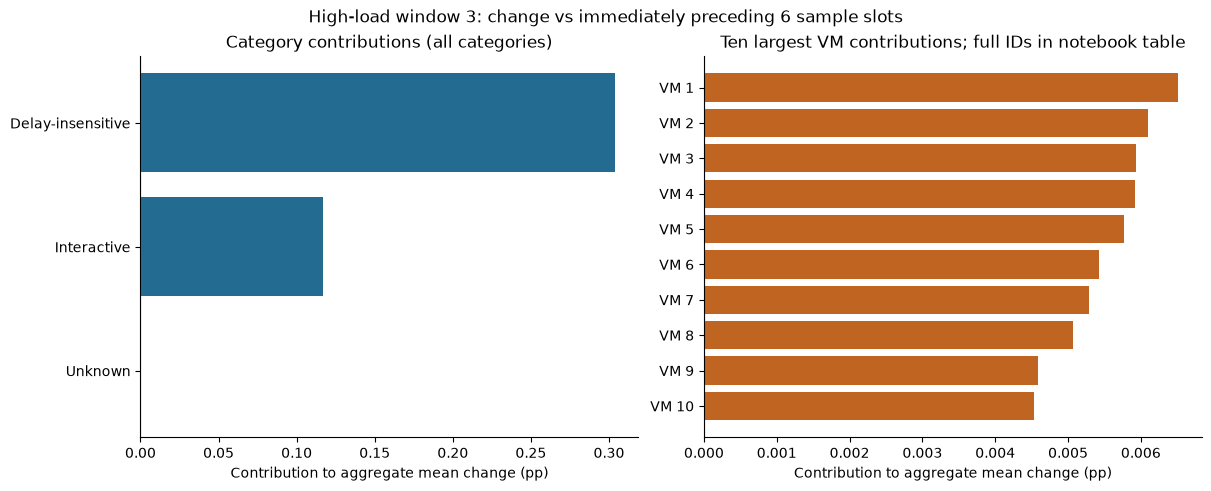

Category,Change contribution (pp),Window
Delay-insensitive,0.30354,3
Interactive,0.11665,3
Unknown,0.00003,3


Chart label,VM ID prefix,Category,Change contribution (pp)
VM 1,xLbiuzphbqoX…,Interactive,0.00651
VM 2,FuPAltRYofeg…,Delay-insensitive,0.00609
VM 3,kh/6413GN7s2…,Unknown,0.00593
VM 4,69jmcDGmfLiM…,Interactive,0.00592
VM 5,HRNaJr/Rpvbw…,Delay-insensitive,0.00577
VM 6,1dk8/UtEXYRg…,Delay-insensitive,0.00542
VM 7,IJwhl5pq7AFR…,Delay-insensitive,0.00529
VM 8,sMC9qldiNCTi…,Delay-insensitive,0.00507
VM 9,tf5blsG6zsfU…,Interactive,0.00459
VM 10,HCOc8X03izdP…,Interactive,0.00453


Chart label,vm_id,contribution_pp
VM 1,xLbiuzphbqoXdNr6alqeOWgbQIBpVcXx3qsG+PG93sIGEXAZ/dPuIQgwuNqYtdgw,0.006509
VM 2,FuPAltRYofegqlNqyZM4oP5Oliq3f4fyKRONHZhfE+Rea7KQC7N2ScjVBTZH2AKK,0.006091
VM 3,kh/6413GN7s2TlbhMtM8fhiv426kbYFBJDeUcqk61ebzyuPxAWO3ZaEc6YsP2wpM,0.005928
VM 4,69jmcDGmfLiMSteNYszcN9pcTL/ZEXvHdPbxZ88hUbE3yQg9U04+VspNDJyvX/OC,0.005925
VM 5,HRNaJr/RpvbwPPU4h4lnEIBm2Oo7BwRa/mXokUowLP9KCyJw17o8u+ythe5fs//q,0.005774
VM 6,1dk8/UtEXYRgHLiNsfRdy0V/zY3U+4qwkiWyGEnc8J9o/PcMLiK/Tj69qJwPiQZB,0.005422
VM 7,IJwhl5pq7AFR+dFd/srKaVA7Qim+Dga3dMTfos9umoTXZLFrMJDrFopwYNipUJZJ,0.005289
VM 8,sMC9qldiNCTil9DOTazEfMNLxI38hzntrKD27Tusb0XOpl8VS3MEywJXlQ6maQ3/,0.005074
VM 9,tf5blsG6zsfUJDSqrN2Wyas9sINsEg8QEbSqbYieUw11Ln10puKi0wD2+prL/5/i,0.004593
VM 10,HCOc8X03izdPeSTZiwZx2ZK4+rqiABno3wtNONWSB/LuP5sAcy9l8ywy+FQyHZwo,0.004531


In [8]:
window_id = m["primary_peak_window_id"]
primary = analysis["peaks"].query("window_id == @window_id").iloc[0]
fig = plot_peak_drivers(analysis)
save_figure(fig, FIGURES, "workload_peak_drivers.png")
plt.show()
display(analysis["category_drivers"].query("window_id == @window_id").rename(columns={"vm_category":"Category", "contribution_pp":"Change contribution (pp)", "window_id":"Window"})
    .style.hide(axis="index").format({"Change contribution (pp)":"{:.5f}"}))
top_vms = analysis["vm_drivers"].query("window_id == @window_id").nlargest(10, "contribution_pp").copy()
top_vms.insert(0, "Chart label", [f"VM {i}" for i in range(1, len(top_vms) + 1)])
top_vms["VM ID prefix"] = top_vms.vm_id.astype(str).str[:12] + "…"
display(top_vms[["Chart label", "VM ID prefix", "vm_category", "contribution_pp"]]
    .rename(columns={"vm_category":"Category", "contribution_pp":"Change contribution (pp)"})
    .style.hide(axis="index").format({"Change contribution (pp)":"{:.5f}"}))
display(HTML("<details><summary>Expand: full anonymized IDs for the ten ranked VMs</summary>"
    + top_vms[["Chart label", "vm_id", "contribution_pp"]].to_html(index=False, escape=True, float_format=lambda x: f"{x:.6f}")
    + "</details>"))
reconciled = analysis["vm_drivers"].query("window_id == @window_id").contribution_pp.sum()
assert np.isclose(reconciled, primary.increase_pp)


In [9]:
# Keep complete evidence tables available without committing large generated data.
for name, value in analysis.items():
    if isinstance(value, pd.DataFrame):
        value.to_csv(TABLES / f"{name}.csv", index=False)
summary = {
    "metrics": analysis["metrics"],
    "indicators": analysis["indicators"].to_dict(orient="records"),
    "categories": analysis["categories"].to_dict(orient="records"),
    "concentration": analysis["concentration"].to_dict(orient="records"),
    "change_candidates": analysis["change_candidates"].to_dict(orient="records"),
    "peaks": analysis["peaks"].to_dict(orient="records"),
    "lows": analysis["lows"].to_dict(orient="records"),
    "lag1": analysis["correlations"].iloc[0].to_dict(),
    "primary_category_drivers": analysis["category_drivers"].query("window_id == @window_id").to_dict(orient="records"),
    "top_segments": analysis["segments"].nlargest(5, "high_load_cpu_share_pct").to_dict(orient="records"),
}
# JSON null represents unavailable descriptive quantities (e.g. a net decline).
def json_ready(value):
    if isinstance(value, dict):
        return {key: json_ready(item) for key, item in value.items()}
    if isinstance(value, list):
        return [json_ready(item) for item in value]
    if isinstance(value, (float, np.floating)) and not np.isfinite(value):
        return None
    return value
(TABLES / "summary.json").write_text(json.dumps(json_ready(summary), indent=2, allow_nan=False), encoding="utf-8")


11389